# Reflection + Evaluator-Optimizer

Agent가 자기 출력을 검토하고 개선하는 패턴을 배운다.

In [1]:
from operator import add
from typing import Annotated, TypedDict

from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from pydantic import BaseModel, Field


load_dotenv()

MODEL_NAME = "gemini-3.6-flash"

### Reflection 패턴

가장 단순한 자기 개선 루프다.

```
START → generate → should_continue? → END (종료)
          ↑                │ continue
          └──── reflect ←──┘
```

동작 순서:

1. **generate** 노드가 초안을 작성한다
2. **should_continue**가 반복 횟수를 체크한다 — 상한에 도달하면 최종 초안을 남기고 종료한다
3. 종료 전이면 **reflect** 노드가 초안을 읽고 피드백을 준다 (톤, 빠진 정보, 길이 등)
4. 피드백을 반영해 다시 generate로 돌아간다

State에 `messages`를 누적하므로 generate 노드는 이전 피드백을 자연스럽게 참고한다.

### Reflection 실습

시나리오: 고객에게 보내는 사과 이메일 초안을 작성하고, 반복적으로 개선한다.

In [2]:
class ReflectionState(TypedDict):
    messages: Annotated[list, add_messages]
    iteration: int


MAX_ITERATIONS = 3
generator_llm = ChatGoogleGenerativeAI(model=MODEL_NAME)
reviewer_llm = ChatGoogleGenerativeAI(model=MODEL_NAME)

In [3]:
def generate(state: ReflectionState):
    """초안을 작성하거나 피드백을 반영해 수정한다."""
    system = SystemMessage(content="""
너는 고객 지원 이메일 작성 전문가다.

사용자의 요청에 맞는 이메일을 작성하라. 대화에 리뷰 피드백이 있으면 빠짐없이 반영하되,
피드백이나 수정 과정을 언급하지 말고 자연스럽게 완성된 이메일로 작성하라.

작성 원칙:
- 상황과 책임을 명확하게 설명한다.
- 진정성 있게 사과하고 구체적인 해결 방안을 안내한다.
- 불필요하게 장황하거나 과장된 표현은 피한다.
- 사용자가 제공한 이름, 주문번호 등 사실을 정확하게 유지한다.

출력 형식:
- 이메일 본문만 출력한다.
- 작성 과정, 해설, 머리말은 출력하지 않는다.
""")
    # 전체 messages를 넘기면 generate는 이전 피드백까지 자연스럽게 참고한다
    response = generator_llm.invoke([system, *state["messages"]])
    return {
        "messages": [AIMessage(content=response.text)],
        "iteration": state.get("iteration", 0) + 1,
    }


def reflect(state: ReflectionState):
    """초안을 검토하고 구체적인 피드백을 준다."""
    system = SystemMessage(content="""
너는 고객 지원 이메일 편집자다. 주어진 초안을 검토하고 다음 수정에 바로 사용할 수 있는
구체적인 피드백을 작성하라. 이메일을 대신 다시 쓰지는 않는다.

검토 기준:
- 사과의 진정성과 책임 있는 태도가 드러나는가?
- 문제 상황과 고객에게 미치는 영향이 명확한가?
- 구체적인 해결 방안이나 다음 조치가 포함되어 있는가?
- 고객명, 주문번호 등 제공된 정보가 정확한가?
- 간결하고 자연스러운 비즈니스 문장인가?

출력 형식:
- 개선이 필요한 항목만 불릿 목록으로 작성한다.
- 각 항목에는 문제점과 수정 방향을 함께 적는다.
- 칭찬, 총평, 점수는 출력하지 않는다.
""")
    # 첫 메시지는 원래 요청이고, reflect는 generate 직후 실행되므로 마지막 메시지는 최신 초안이다
    original_request = state["messages"][0]
    latest_draft = state["messages"][-1]
    response = reviewer_llm.invoke([
        system,
        HumanMessage(content=(
            f"<request>\n{original_request.text}\n</request>\n\n"
            f"<draft>\n{latest_draft.text}\n</draft>"
        )),
    ])
    # HumanMessage로 넣는 이유: generate 노드의 LLM 입장에서 피드백은
    # "사용자 지시"처럼 작용해야 하므로 AIMessage가 아닌 HumanMessage로 넣는다
    return {
        "messages": [HumanMessage(content=response.text)],
    }


def should_continue(state: ReflectionState):
    if state["iteration"] >= MAX_ITERATIONS:
        return "end"
    return "continue"

In [4]:
builder = StateGraph(ReflectionState)

builder.add_node("generate", generate)
builder.add_node("reflect", reflect)

builder.add_edge(START, "generate")
builder.add_conditional_edges(
    "generate",
    should_continue,
    {"continue": "reflect", "end": END},
)
builder.add_edge("reflect", "generate")

reflection_graph = builder.compile()

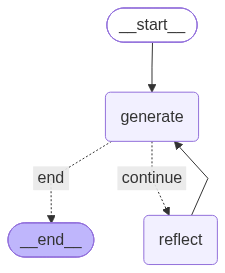

In [5]:
display(Image(reflection_graph.get_graph().draw_mermaid_png()))

In [6]:
task = "배송이 2주 지연된 고객에게 사과 이메일을 작성해줘. 고객명: 김민수, 주문번호: ORD-2024-1234"

result = reflection_graph.invoke(
    {"messages": [HumanMessage(content=task)], "iteration": 0}
)

print(f"총 반복 횟수: {result['iteration']}")
print(f"총 메시지 수: {len(result['messages'])}")
print("\n" + "=" * 60)

for msg in result["messages"]:
    print(f"\n[{msg.type}]")
    print(msg.text[:500])
    print("-" * 40)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


총 반복 횟수: 3
총 메시지 수: 6


[human]
배송이 2주 지연된 고객에게 사과 이메일을 작성해줘. 고객명: 김민수, 주문번호: ORD-2024-1234
----------------------------------------

[ai]
제목: [주문번호: ORD-2024-1234] 배송 지연에 대한 사과의 말씀 드립니다.

김민수 고객님, 안녕하십니까.

먼저 저희 제품을 믿고 구매해 주신 고객님께 상품 배송 지연으로 큰 불편을 드려 진심으로 사과의 말씀을 드립니다.

고객님께서 주문하신 상품(주문번호: ORD-2024-1234)이 당초 안내해 드린 일정보다 약 2주가량 배송이 지연되고 있습니다. 최근 주문량 증가에 따른 물류 검수 과정에서 차질이 발생하여 예정된 출고 일정을 준수하지 못했습니다. 배송 과정을 철저히 관리하지 못해 오랜 시간 기다리시게 한 점 고개 숙여 사과드립니다.

현재 지연된 상품은 물류센터에서 최우선으로 출고 준비를 마쳤으며, 오는 [X월 X일]까지 고객님께 안전하게 전달될 예정입니다. 상품이 발송되는 즉시 운송장 번호를 문자 메시지로 안내해 드리겠습니다.

오랜 시간 기다려 주신 김민수 고객님께 죄송한 마음을 담아, 다음 구매 시 사용하실 수 있는 소정의 보상 쿠폰을 계정에 발급해 드렸습니
----------------------------------------

[human]
- **구체적인 예상 배송일 미기입**
  - 문제점: 본문 내 `[X월 X일]` 플레이스홀더가 그대로 남아 있어 고객이 실제 상품 수령 날짜를 알 수 없습니다.
  - 수정 방향: 실제 안내 가능한 정확한 배송 예정일(예: 10월 25일 등)로 수정해야 합니다.

- **보상 내용의 모호함**
  - 문제점: '소정의 보상 쿠폰'이라는 표현이 구체적이지 않아 고객이 얻는 혜택을 직관적으로 파악하기 어렵습니다.
  - 수정 방향: 발급된 쿠폰의 할인 금액(또는 할인율), 쿠폰명, 유효기간 등의 상세 정보를 명시해야 합니다.

- **발송자 정보 미입

반복할수록 피드백이 반영되어 품질이 올라가는 것을 확인할 수 있다. 하지만 Reflection에는 한계가 있다.

- 피드백이 **자연어**라서 "얼마나 좋아졌는지" 정량화할 수 없다
- "충분히 좋다"의 기준이 없으므로 항상 `max_iterations`까지 반복한다
- 반복할수록 피드백이 점점 미세해져 표현 수준의 차이만 지적할 수 있다. 이것이 실질적 개선인지는 별도로 판단해야 한다
- 반복이 많아지면 원래 의도에서 벗어나거나 과하게 수정되는 경우도 있다 (항상 품질이 올라가는 것은 아니다)

Evaluator-Optimizer 패턴은 루브릭과 합격 기준을 명시해 종료 시점과 개선 대상을 더 분명하게 만든다. 다만 평가자가 LLM이라면 점수의 주관성과 실행별 변동성은 여전히 남는다.

### Evaluator-Optimizer 패턴

Reflection과 구조는 비슷하지만 핵심 차이가 있다.

| | Reflection | Evaluator-Optimizer |
|---|---|---|
| 평가 결과 | 자유 형식의 자연어 피드백 | 항목별 점수와 근거를 구조화해 반환 |
| 종료 조건 | 주로 고정 횟수 | 합격 기준 달성 또는 최대 횟수 도달 |
| 개선 범위 | 전체적인 피드백 | 기준에 미달한 항목을 우선 개선 |
| 판정 특성 | 종료 판단이 명시적이지 않음 | 기준은 명시적이지만 LLM 점수는 달라질 수 있음 |

```
START → generate → evaluate → pass → END
          ↑            │ fail
          └── optimize ←┘
```

시나리오: 마케팅 카피 생성. 루브릭으로 평가하고, 미달 항목에 대한 수정 지시를 만든 뒤 다시 생성한다. 점수는 품질을 객관적으로 보장하는 값이 아니라 흐름을 제어하기 위한 구조화된 판단으로 사용한다.

### 루브릭 설계

루브릭(Rubric)은 **평가 항목과 점수 기준을 정리한 채점표**다. 좋은 루브릭은 구체적이고 측정 가능하다.

| 나쁜 루브릭 | 좋은 루브릭 |
|------------|------------|
| "매력적인가?" | "감정을 자극하는 단어가 1개 이상 포함되어 있는가?" |
| "적절한 길이인가?" | "50자 이상 150자 이하인가?" |
| "좋은 카피인가?" | "행동 유도(CTA)가 포함되어 있는가?" |

Pydantic 모델로 평가 결과를 구조화한다.

In [7]:
class CriterionResult(BaseModel):
    score: int = Field(description="1~10 점수", ge=1, le=10)
    reason: str = Field(description="점수 근거 (1문장)")


class EvaluationResult(BaseModel):
    clarity: CriterionResult = Field(description="핵심 가치 전달 평가")
    emotion: CriterionResult = Field(description="타겟 공감과 변화 표현 평가")
    cta: CriterionResult = Field(description="행동 유도 평가")
    conciseness: CriterionResult = Field(description="길이와 중복 표현 평가")
    summary: str = Field(description="전체 평가 요약 (1~2문장)")

루브릭은 도메인마다 완전히 달라진다. 마케팅 카피라면 "감정 자극, CTA 포함, 글자 수", 기술 문서라면 "정확성, 재현 가능성, 코드 포함" 등이 핵심 기준이 된다. 설계할 때는 해당 도메인의 핵심 품질 기준을 먼저 정의하고, 각 기준을 측정 가능한 형태로 변환한 뒤, 점수 척도와 합격 기준을 설정한다.

In [13]:
class EvalOptState(TypedDict):
    task: str
    copy: str
    evaluation: dict  # EvaluationResult를 dict로 저장
    iteration: int
    history: Annotated[list, add]  # 이전 카피, 평가 결과, 개선 지시 누적


MAX_ITERATIONS = 4
PASS_THRESHOLD = 8
EVALUATION_CRITERIA = ("clarity", "emotion", "cta", "conciseness")
evaluator_llm = ChatGoogleGenerativeAI(model=MODEL_NAME)
evaluator = evaluator_llm.with_structured_output(EvaluationResult)

In [14]:
def generate_copy(state: EvalOptState):
    """마케팅 카피를 생성한다. 이전 평가가 있으면 optimize 노드의 지시를 참고한다."""
    task = state["task"]
    history = state.get("history", [])

    if history:
        last = history[-1]
        prompt = (
            f"작업: {task}\n\n"
            f"이전 카피:\n{last['copy']}\n\n"
            f"개선 지시:\n{last['improvement']}\n\n"
            "위 지시를 반영해서 카피를 다시 작성해. 카피만 출력해."
        )
    else:
        prompt = f"다음 마케팅 카피를 작성해. 카피만 출력해.\n\n작업: {task}"

    response = generator_llm.invoke(prompt)
    return {"copy": response.text}


def evaluate_copy(state: EvalOptState):
    """루브릭에 따라 카피를 채점한다. Structured Output 사용."""
    copy = state["copy"]
    system = SystemMessage(content="""
너는 마케팅 카피 평가자다. 각 항목을 1~10점으로 평가하고 근거를 한 문장으로 작성하라.

평가 기준:
- clarity: 출퇴근 10분과 영어 실력 향상을 모두 명확히 전달하면 8점 이상
- emotion: 타겟이 공감할 문제나 기대할 변화를 구체적으로 표현하면 8점 이상
- cta: 독자가 즉시 실행할 수 있는 직접적인 행동 유도가 있으면 8점 이상
- conciseness: 공백 포함 50~150자이고 중복 표현이 없으면 8점 이상

기준을 충족하지 못한 항목에는 7점 이하를 부여하라.
""")
    result = evaluator.invoke([
        system,
        HumanMessage(content=f"<copy>\n{copy}\n</copy>"),
    ])

    evaluation = result.model_dump()
    evaluation["overall_pass"] = all(
        evaluation[name]["score"] >= PASS_THRESHOLD
        for name in EVALUATION_CRITERIA
    )

    return {
        "evaluation": evaluation,
        "iteration": state.get("iteration", 0) + 1,
    }


def optimize_copy(state: EvalOptState):
    """미달 항목의 평가 근거를 바탕으로 다음 생성에 사용할 수정 지시를 만든다."""
    evaluation = state["evaluation"]
    failed = [
        (name, evaluation[name])
        for name in EVALUATION_CRITERIA
        if evaluation[name]["score"] < PASS_THRESHOLD
    ]
    failed_items = [
        f"- {name} ({criterion['score']}점): {criterion['reason']}"
        for name, criterion in failed
    ]

    response = generator_llm.invoke(
        """너는 마케팅 카피 개선 편집자다. 평가 기준에 미달한 항목만 분석해
다음 생성 단계가 바로 적용할 수 있는 구체적인 수정 지시를 작성하라.
카피를 직접 다시 쓰지 말고, 유지할 내용과 바꿀 내용을 명확히 구분하라.
평가에 없는 새로운 제품 정보는 추가하지 마라.

<task>
""" + state["task"] + """
</task>

<current_copy>
""" + state["copy"] + """
</current_copy>

<failed_criteria>
""" + "\n".join(failed_items) + """
</failed_criteria>"""
    )

    return {
        "history": [{
            "copy": state["copy"],
            "evaluation": evaluation,
            "improvement": response.text,
        }],
    }


def should_continue_eval(state: EvalOptState):
    if state["evaluation"]["overall_pass"]:
        return "end"
    if state["iteration"] >= MAX_ITERATIONS:
        return "end"  # 상한 도달 시에도 종료
    return "fail"

In [15]:
builder = StateGraph(EvalOptState)

builder.add_node("generate", generate_copy)
builder.add_node("evaluate", evaluate_copy)
builder.add_node("optimize", optimize_copy)

builder.add_edge(START, "generate")
builder.add_edge("generate", "evaluate")
builder.add_conditional_edges(
    "evaluate",
    should_continue_eval,
    {"end": END, "fail": "optimize"},
)
builder.add_edge("optimize", "generate")

eval_opt_graph = builder.compile()

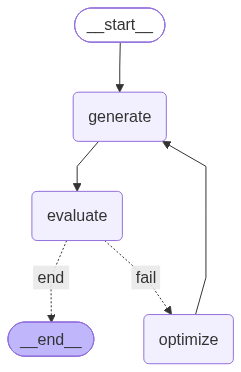

In [11]:
display(Image(eval_opt_graph.get_graph().draw_mermaid_png()))

In [12]:
task = "AI 기반 영어 학습 앱 'SmartLingo' 출시 광고 카피. 타겟: 20~30대 직장인. 핵심 가치: 출퇴근 10분으로 영어 실력 향상."

for event in eval_opt_graph.stream({"task": task, "iteration": 0, "history": []}):
    node_name = list(event.keys())[0]
    state_update = event[node_name]

    if node_name == "generate":
        print(f"\n{'=' * 60}")
        print(f"[generate] 카피 생성")
        print(state_update["copy"])

    elif node_name == "evaluate":
        iteration = state_update["iteration"]
        evaluation = state_update["evaluation"]
        status = "PASS ✓" if evaluation["overall_pass"] else "FAIL ✗"
        print(f"\n[evaluate] 반복 {iteration} — {status}")
        for name in EVALUATION_CRITERIA:
            criterion = evaluation[name]
            mark = "PASS" if criterion["score"] >= PASS_THRESHOLD else "FAIL"
            print(f"  {name}: {criterion['score']}/10 ({mark}) - {criterion['reason']}")

    elif node_name == "optimize":
        h = state_update["history"][0]
        print(f"\n[optimize] 개선 지시")
        print(h["improvement"])


[generate] 카피 생성
**출퇴근길 10분, AI로 완성하는 내 손안의 1:1 영어 학원**

매일 버스와 지하철에서 버리던 자투리 시간,
이제 당신의 커리어를 바꿀 10분으로 만드세요.

바쁜 직장인을 위해 AI가 딱 맞춘 영어 학습 앱, **SmartLingo**

• 내 실력에 맞춘 AI 1:1 밀착 튜터링
• 출퇴근길에 부담 없이 끝내는 10분 숏폼 학습
• 비즈니스부터 일상 회화까지 필요한 표현만 쏙쏙

영어 공부, 더 이상 미루지 마세요. 
지금 'SmartLingo'로 10분의 기적을 시작해 보세요!

[evaluate] 반복 1 — FAIL ✗
  clarity: 9/10 (PASS) - 출퇴근 10분 활용과 영어 학습을 통한 커리어 향상이라는 핵심 이점을 명확하게 전달하고 있습니다.
  emotion: 9/10 (PASS) - 출퇴근길에 버려지는 자투리 시간이라는 직장인의 공감대와 커리어 변화에 대한 기대를 잘 자극하고 있습니다.
  cta: 9/10 (PASS) - '지금 SmartLingo로 10분의 기적을 시작해 보세요!'라는 직접적이고 즉각적인 행동 유도 문구가 포함되어 있습니다.
  conciseness: 6/10 (FAIL) - 공백 포함 글자 수가 150자를 크게 초과하여 다소 길게 느껴지며 10분 및 AI 강조가 반복됩니다.

[optimize] 개선 지시
[평가 미달 항목 분석 및 수정 지시]

**미달 항목: conciseness (간결성 - 6점)**
*   **분석:** 공백 포함 전체 글자 수가 약 250자로 기준치인 150자를 크게 초과합니다. 또한 핵심 키워드인 **'10분'이 4회**, **'AI'가 3회** 반복되어 카피가 다소 산만하고 길게 느껴집니다.

---

### 1. 유지할 내용 (Keep)
*   **타깃 및 상황 설정:** 20~30대 직장인의 '출퇴근길' 맥락
*   **핵심 가치 요상:** '10분 숏폼 학습'과 'AI 맞춤 튜터링'이라는 제품의 본질적 혜택
*   **브랜드명:** 'S

주의: 이 예제에서는 같은 LLM이 생성과 평가를 모두 수행한다. 합격 규칙을 코드로 고정해도 LLM이 매기는 점수는 실행마다 달라질 수 있다. 실무에서는 평가에 더 강한 모델을 쓰거나, 생성 모델과 별도의 모델을 사용해서 자기 평가 편향(self-evaluation bias)을 줄이기도 한다.

### 실습: 제품 리뷰 요약

아래 제품 리뷰를 한 문단(3~5문장)으로 요약하는 과제를 두 가지 패턴으로 구현한다.

- **Reflection**: generate → should_continue → reflect 루프
- **Evaluator-Optimizer**: generate → evaluate → optimize 루프

실무에서 Evaluator-Optimizer를 쓸 때 **루브릭 설계가 가장 중요한 단계**다. 루브릭이 모호하면 점수가 들쭉날쭉해서 Reflection과 다를 바 없고, 루브릭이 구체적이면 개선 방향이 명확해진다.

### 샘플 리뷰 데이터

In [16]:
REVIEW = """\
[무선 블루투스 이어폰 - StarBuds Pro 리뷰]

저는 이 이어폰을 출퇴근용으로 3개월째 사용하고 있습니다. 먼저 음질은 가격대비 정말 \
훌륭합니다. 저음이 풍부하고 고음도 깨끗하게 들립니다. 특히 팟캐스트를 들을 때 목소리가 \
또렷하게 들려서 좋습니다.

노이즈 캔슬링은 지하철에서 테스트해봤는데, 완전 차단까지는 아니지만 주변 소음을 \
70~80% 정도 줄여줍니다. 출퇴근 시 음악 감상에는 충분합니다. 다만 바람이 부는 야외에서는 \
노캔 성능이 많이 떨어집니다.

배터리는 공식 스펙이 7시간인데 실사용 5시간 반 정도 갑니다. 노캔 켜면 4시간 정도로 \
줄어듭니다. 케이스 충전 포함하면 총 20시간 정도 사용 가능합니다.

착용감은 제 귀에는 잘 맞는데, 귀가 작은 아내는 30분만 끼면 아프다고 합니다. 이어팁이 \
3종류 들어있긴 한데 가장 작은 것도 좀 큰 편입니다.

통화 품질은 솔직히 별로입니다. 상대방이 제 목소리가 멀리서 들린다고 합니다. \
조용한 실내에서는 괜찮은데 밖에서는 통화하기 어렵습니다.

앱 연동은 EQ 조절이 가능하고 노캔 강도도 조절할 수 있어서 편리합니다. \
다만 앱이 가끔 블루투스 연결이 끊기는 버그가 있습니다.

총평: 7만원대에 이 정도면 가성비 좋습니다. 통화보다 음악 감상 위주로 쓸 분께 추천합니다. \
통화를 많이 하시는 분은 다른 제품을 알아보시는 게 좋을 것 같습니다.
"""

print(REVIEW)

[무선 블루투스 이어폰 - StarBuds Pro 리뷰]

저는 이 이어폰을 출퇴근용으로 3개월째 사용하고 있습니다. 먼저 음질은 가격대비 정말 훌륭합니다. 저음이 풍부하고 고음도 깨끗하게 들립니다. 특히 팟캐스트를 들을 때 목소리가 또렷하게 들려서 좋습니다.

노이즈 캔슬링은 지하철에서 테스트해봤는데, 완전 차단까지는 아니지만 주변 소음을 70~80% 정도 줄여줍니다. 출퇴근 시 음악 감상에는 충분합니다. 다만 바람이 부는 야외에서는 노캔 성능이 많이 떨어집니다.

배터리는 공식 스펙이 7시간인데 실사용 5시간 반 정도 갑니다. 노캔 켜면 4시간 정도로 줄어듭니다. 케이스 충전 포함하면 총 20시간 정도 사용 가능합니다.

착용감은 제 귀에는 잘 맞는데, 귀가 작은 아내는 30분만 끼면 아프다고 합니다. 이어팁이 3종류 들어있긴 한데 가장 작은 것도 좀 큰 편입니다.

통화 품질은 솔직히 별로입니다. 상대방이 제 목소리가 멀리서 들린다고 합니다. 조용한 실내에서는 괜찮은데 밖에서는 통화하기 어렵습니다.

앱 연동은 EQ 조절이 가능하고 노캔 강도도 조절할 수 있어서 편리합니다. 다만 앱이 가끔 블루투스 연결이 끊기는 버그가 있습니다.

총평: 7만원대에 이 정도면 가성비 좋습니다. 통화보다 음악 감상 위주로 쓸 분께 추천합니다. 통화를 많이 하시는 분은 다른 제품을 알아보시는 게 좋을 것 같습니다.



### Reflection으로 리뷰 요약

위에서 배운 Reflection 패턴을 사용해서 리뷰를 한 문단(3~5문장)으로 요약하는 그래프를 구현하라. 장점, 단점, 추천 대상을 균형 있게 포함하고, 반복적인 검토를 통해 요약을 개선한다.

In [36]:
# 완성한 그래프를 review_reflection_graph에 저장하세요.
class ReviewReflectionState(TypedDict):
    messages: Annotated[list, add_messages]
    iteration: int

MAX_ITERATIONS = 3
generator_llm = ChatGoogleGenerativeAI(model=MODEL_NAME)
reviewer_llm = ChatGoogleGenerativeAI(model=MODEL_NAME)

In [37]:
def generate(state: ReviewReflectionState):
    """리뷰를 요약하고 피드백을 반영해 요약을 수정한다."""
    system = SystemMessage(content="""
너는 리뷰 요약 전문가다.

해당 리뷰를 한 문단(3문장 ~ 5문장)으로 요약하고, 대화에 리뷰 피드백이 있으면 빠짐없이 반영하되,
피드백이나 수정 과정을 언급하지 말고 자연스럽게 완성된 요약으로 작성하라. 

리뷰에 없던 사실을 추가하지 않는다. 

출력 형식:
- 리뷰 본문만 출력한다.
""")
    # 전체 messages를 넘기면 generate는 이전 피드백까지 자연스럽게 참고한다
    response = generator_llm.invoke([system, *state["messages"]])
    return {
        "messages": [AIMessage(content=response.text)],
        "iteration": state.get("iteration", 0) + 1,
    }


def reflect(state: ReflectionState):
    """요약문을 검토하고 구체적인 피드백을 준다."""
    system = SystemMessage(content="""
너는 리뷰 요약 평가자이다. 주어진 리뷰의 요약을 검토하고 다음 수정에 바로 사용할 수 있는
구체적인 피드백을 작성하라. 대신 다시 쓰지는 않는다.

검토 기준:
- 없던 내용을 임의로 추가하지는 않았는가
- 리뷰에서 중요한 정보를 누락하지는 않았는가 
- 장점, 단점, 추천 대상을 균형 있게 포함하였는가 

출력 형식:
- 개선이 필요한 항목만 불릿 목록으로 작성한다.
- 각 항목에는 문제점과 수정 방향을 함께 적는다.
- 칭찬, 총평, 점수는 출력하지 않는다.
""")
    # 첫 메시지는 원래 요청이고, reflect는 generate 직후 실행되므로 마지막 메시지는 최신 초안이다
    original_request = state["messages"][0]
    latest_draft = state["messages"][-1]
    response = reviewer_llm.invoke([
        system,
        HumanMessage(content=(
            f"<request>\n{original_request.text}\n</request>\n\n"
            f"<draft>\n{latest_draft.text}\n</draft>"
        )),
    ])
    # HumanMessage로 넣는 이유: generate 노드의 LLM 입장에서 피드백은
    # "사용자 지시"처럼 작용해야 하므로 AIMessage가 아닌 HumanMessage로 넣는다
    return {
        "messages": [HumanMessage(content=response.text)],
    }


def should_continue(state: ReflectionState):
    if state["iteration"] >= MAX_ITERATIONS:
        return "end"
    return "continue"

In [38]:
result = reflection_graph.invoke(
    {"messages": [HumanMessage(content=task)], "iteration": 0}
)

print(f"총 반복 횟수: {result['iteration']}")
print(f"총 메시지 수: {len(result['messages'])}")
print("\n" + "=" * 60)

for msg in result["messages"]:
    print(f"\n[{msg.type}]")
    print(msg.text[:500])
    print("-" * 40)

총 반복 횟수: 3
총 메시지 수: 6


[human]
[무선 블루투스 이어폰 - StarBuds Pro 리뷰]

저는 이 이어폰을 출퇴근용으로 3개월째 사용하고 있습니다. 먼저 음질은 가격대비 정말 훌륭합니다. 저음이 풍부하고 고음도 깨끗하게 들립니다. 특히 팟캐스트를 들을 때 목소리가 또렷하게 들려서 좋습니다.

노이즈 캔슬링은 지하철에서 테스트해봤는데, 완전 차단까지는 아니지만 주변 소음을 70~80% 정도 줄여줍니다. 출퇴근 시 음악 감상에는 충분합니다. 다만 바람이 부는 야외에서는 노캔 성능이 많이 떨어집니다.

배터리는 공식 스펙이 7시간인데 실사용 5시간 반 정도 갑니다. 노캔 켜면 4시간 정도로 줄어듭니다. 케이스 충전 포함하면 총 20시간 정도 사용 가능합니다.

착용감은 제 귀에는 잘 맞는데, 귀가 작은 아내는 30분만 끼면 아프다고 합니다. 이어팁이 3종류 들어있긴 한데 가장 작은 것도 좀 큰 편입니다.

통화 품질은 솔직히 별로입니다. 상대방이 제 목소리가 멀리서 들린다고 합니다. 조용한 실내에서는 괜찮은데 밖에서는
----------------------------------------

[ai]
제목: [StarBuds Pro] 소중한 제품 후기에 대한 감사 및 불편 사항 안내의 건

안녕하세요, 고객님. StarBuds 고객지원팀입니다.

저희 StarBuds Pro 제품을 3개월 동안 출퇴근길에 사용해 주시고, 음질과 노이즈 캔슬링 기능 등 여러 측면에서 상세하고 귀중한 피드백을 남겨주셔서 진심으로 감사드립니다.

고객님께서 제품을 사용하시면서 만족하신 점 외에 아내분과 함께 겪으신 불편 사항들에 대해 책임을 통감하며, 이에 대한 개선 및 해결 방안을 안내해 드리고자 합니다.

**1. 착용감 및 이어팁 크기 문제**
아내분께서 가장 작은 이어팁을 사용하셨음에도 귀에 통증을 느끼셨다니 마음이 편치 않습니다. 당사에서는 귀가 작은 고객님들을 위해 기본 구성품 외에 **'초소형(SS) 이어팁'**을 별도로 보유하고 있습니다. 본 이메

### Evaluator-Optimizer로 리뷰 요약

같은 리뷰를 Evaluator-Optimizer 패턴으로 요약한다. 아래 루브릭은 구현을 돕기 위한 참고 예시이며, 그대로 사용할 필요는 없다. 필요에 따라 평가 항목과 기준을 수정하거나 추가한다. 모든 항목이 8점 이상이면 통과한다.

루브릭 (각 1~10점):
- completeness: 원문의 핵심 장점과 단점이 각각 1개 이상 포함되고, 가격 정보가 반영되었는가?
- accuracy: 가격, 사용 시간, 성능 등 제품 정보가 원문과 일치하며, 원문에 없는 정보를 추가하지 않았는가?
- conciseness: 핵심 정보의 불필요한 반복 없이 3~5문장으로 작성되었는가?
- recommendation: 적합한 사용자와 부적합한 사용자를 원문의 근거에 따라 모두 언급했는가?

In [19]:
class CriterionResult(BaseModel):
    score: int = Field(description="1~10 점수", ge=1, le=10)
    reason: str = Field(description="점수 근거 (1문장)")


class EvaluationResult(BaseModel):
    completeness: CriterionResult = Field(description="원문의 핵심 정보 반영 평가")
    accuracy: CriterionResult = Field(description="원문 일치 평가")
    recommendation: CriterionResult = Field(description="적합/부적합 사용자 평가")
    conciseness: CriterionResult = Field(description="길이와 중복 표현 평가")
    summary: str = Field(description="전체 평가 요약 (1~2문장)")

In [20]:
class EvalOptState(TypedDict):
    task: str
    copy: str
    evaluation: dict  # EvaluationResult를 dict로 저장
    iteration: int
    history: Annotated[list, add]  # 이전 카피, 평가 결과, 개선 지시 누적


MAX_ITERATIONS = 4
PASS_THRESHOLD = 8
EVALUATION_CRITERIA = ("completeness", "accuracy", "recommendation", "conciseness")
evaluator_llm = ChatGoogleGenerativeAI(model=MODEL_NAME)
evaluator = evaluator_llm.with_structured_output(EvaluationResult)

In [21]:
def generate_copy(state: EvalOptState):
    """제품 리뷰를 요약해주세요. 이전 평가가 있으면 optimize 노드의 지시를 참고한다."""
    task = state["task"]
    history = state.get("history", [])

    if history:
        last = history[-1]
        prompt = (
            f"리뷰: {task}\n\n"
            f"이전 요약:\n{last['copy']}\n\n"
            f"개선 지시:\n{last['improvement']}\n\n"
            "위 지시를 반영해서 리뷰를 다시 요약해. 요약만 출력해."
        )
    else:
        prompt = f"다음 리뷰를 요약해줘. 요약만 출력해\n\n작업: {task}"

    response = generator_llm.invoke(prompt)
    return {"copy": response.text}


def evaluate_copy(state: EvalOptState):
    """루브릭에 따라 리뷰를 채점한다. Structured Output 사용."""
    copy = state["copy"]
    system = SystemMessage(content="""
너는 리뷰 요약 평가자다. 각 항목을 1~10점으로 평가하고 근거를 한 문장으로 작성하라.

평가 기준:
- completeness: 원문의 핵심 장점과 단점이 각각 1개 이상 포함되고, 가격 정보가 반영되었다면 8점 이상
- accuracy: 가격, 사용 시간, 성능 등 제품 정보가 원문과 일치하며, 원문에 없는 정보를 추가하지 않았다면 8점 이상
- conciseness: 핵심 정보의 불필요한 반복 없이 3~5문장으로 작성되었다면 8점 이상
- recommendation: 적합한 사용자와 부적합한 사용자를 원문의 근거에 따라 모두 언급했다면 8점 이상

기준을 충족하지 못한 항목에는 7점 이하를 부여하라.
""")
    result = evaluator.invoke([
        system,
        HumanMessage(content=f"<copy>\n{copy}\n</copy>"),
    ])

    evaluation = result.model_dump()
    evaluation["overall_pass"] = all(
        evaluation[name]["score"] >= PASS_THRESHOLD
        for name in EVALUATION_CRITERIA
    )

    return {
        "evaluation": evaluation,
        "iteration": state.get("iteration", 0) + 1,
    }


def optimize_copy(state: EvalOptState):
    """미달 항목의 평가 근거를 바탕으로 다음 생성에 사용할 수정 지시를 만든다."""
    evaluation = state["evaluation"]
    failed = [
        (name, evaluation[name])
        for name in EVALUATION_CRITERIA
        if evaluation[name]["score"] < PASS_THRESHOLD
    ]
    failed_items = [
        f"- {name} ({criterion['score']}점): {criterion['reason']}"
        for name, criterion in failed
    ]

    response = generator_llm.invoke(
        """너는 리뷰를 요약하는 담당자이다. 평가 기준에 미달한 항목만 분석해
다음 생성 단계가 바로 적용할 수 있는 구체적인 수정 지시를 작성하라.
리뷰를 직접 다시 쓰지 말고, 유지할 내용과 바꿀 내용을 명확히 구분하라.
리뷰에 없는 새로운 정보는 추가하지 마라.

<task>
""" + state["task"] + """
</task>

<current_copy>
""" + state["copy"] + """
</current_copy>

<failed_criteria>
""" + "\n".join(failed_items) + """
</failed_criteria>"""
    )

    return {
        "history": [{
            "copy": state["copy"],
            "evaluation": evaluation,
            "improvement": response.text,
        }],
    }


def should_continue_eval(state: EvalOptState):
    if state["evaluation"]["overall_pass"]:
        return "end"
    if state["iteration"] >= MAX_ITERATIONS:
        return "end"  # 상한 도달 시에도 종료
    return "fail"

In [22]:
# 완성한 그래프를 review_eval_opt_graph에 저장하세요.
# 최종 요약은 summary, 평가 결과는 evaluation에 저장하세요.

builder = StateGraph(EvalOptState)

builder.add_node("generate", generate_copy)
builder.add_node("evaluate", evaluate_copy)
builder.add_node("optimize", optimize_copy)

builder.add_edge(START, "generate")
builder.add_edge("generate", "evaluate")
builder.add_conditional_edges(
    "evaluate",
    should_continue_eval,
    {"end": END, "fail": "optimize"},
)
builder.add_edge("optimize", "generate")

review_eval_opt_graph = builder.compile()

In [27]:
task = REVIEW
final_summary = None
final_evaluation = None

for event in eval_opt_graph.stream(
    {"task": task, "iteration": 0, "history": []}
):
    node_name = list(event.keys())[0]
    state_update = event[node_name]

    if node_name == "generate":
        print(f"\n{'=' * 60}")
        print("[generate] 카피 생성")
        print(state_update["copy"])

    elif node_name == "evaluate":
        iteration = state_update["iteration"]
        evaluation = state_update["evaluation"]

        # 최종 반복까지 계속 덮어쓰기
        final_evaluation = evaluation
        final_summary = evaluation["summary"]

        status = "PASS ✓" if evaluation["overall_pass"] else "FAIL ✗"
        print(f"\n[evaluate] 반복 {iteration} — {status}")

        for name in EVALUATION_CRITERIA:
            criterion = evaluation[name]
            mark = (
                "PASS"
                if criterion["score"] >= PASS_THRESHOLD
                else "FAIL"
            )
            print(
                f"  {name}: {criterion['score']}/10 "
                f"({mark}) - {criterion['reason']}"
            )

    elif node_name == "optimize":
        h = state_update["history"][0]
        print("\n[optimize] 개선 지시")
        print(h["improvement"])


# 그래프가 종료된 후 마지막 평가 결과
print("\n[최종 평가 요약]")
print(final_summary)

print("\n[최종 평가 전체]")
print(final_evaluation)


[generate] 카피 생성
🎧 **7만 원대의 기적, 오롯이 음악에 몰입하는 시간**
**StarBuds Pro (스타버즈 프로)**

매일 반복되는 지루한 출퇴근길, 나만의 콘서트홀이 펼쳐집니다.

✨ **가격대를 뛰어넘는 압도적 사운드**
풍부하게 울리는 저음과 깨끗한 고음! 음악은 더욱 생생하게, 팟캐스트 목소리는 더욱 또렷하게 들려줍니다.

🔇 **지하철 소음 80% 차단**
시끄러운 출퇴근길 도심 속에서도 오롯이 내 음악에만 집중할 수 있는 노이즈 캔슬링 성능.

🎛️ **내 취향대로 즐기는 커스텀 EQ**
전용 앱으로 노이즈 캔슬링 강도 조절부터 디테일한 음색 설정까지 똑똑하게.

*"통화보다는 음악 감상이 먼저인 당신을 위해"*
비싼 가격표는 빼고 사운드 본연의 즐거움만 담았습니다. 

지금 바로 **StarBuds Pro**와 함께 당신의 일상을 음악으로 채워보세요!

[evaluate] 반복 1 — FAIL ✗
  completeness: 4/10 (FAIL) - 출퇴근 10분과 영어 실력 향상에 대한 핵심 내용이 전혀 언급되지 않아 평가 기준을 충족하지 못했습니다.
  accuracy: 5/10 (FAIL) - 이어폰 제품 기능은 명확히 작성되었으나 요구된 주제와 전혀 다른 내용이 작성되어 정확성이 떨어집니다.
  recommendation: 7/10 (FAIL) - 출퇴근길 소음 차단이라는 공감대와 제품 구매를 유도하는 CTA가 포함되어 있으나 핵심 주제에서 벗어나 있습니다.
  conciseness: 4/10 (FAIL) - 공백 포함 글자 수가 약 400자로 기준인 50~150자를 크게 초과하였습니다.

[optimize] 개선 지시
평가 기준에 미달한 항목(**completeness, accuracy, recommendation, conciseness**)을 바탕으로 한 분석 및 구체적인 카피 수정 지시문입니다.

---

### [미달 항목 분석]
1. **Completeness (완전성 - 4점) & Accuracy (정확성 

In [32]:
import pprint

print("\n[최종 평가 요약]")
print(final_summary)

print("\n[최종 평가 전체]")
pprint.pprint(final_evaluation)


[최종 평가 요약]
출퇴근길 영어 학습이라는 핵심 유기성을 명확히 전달하며 소음 차단 기능과 행동 유도까지 간결하게 담아낸 우수한 카피입니다.

[최종 평가 전체]
{'accuracy': {'reason': '지하철 소음 차단과 팟캐스트 전달 등 타겟이 기대할 변화와 공감 요소를 구체적으로 표현했습니다.',
              'score': 9},
 'completeness': {'reason': '출퇴근 10분 활용과 영어 실력 향상이라는 핵심 메시지를 명확하게 전달하고 있습니다.',
                  'score': 9},
 'conciseness': {'reason': '공백 포함 약 107자로 기준 범위인 50~150자를 충족하며 중복 표현 없이 간결합니다.',
                 'score': 9},
 'overall_pass': True,
 'recommendation': {'reason': '지금 출퇴근길에서 영어 실력을 높여보라는 직접적이고 실행 가능한 행동 유도가 포함되어 '
                              '있습니다.',
                    'score': 8},
 'summary': '출퇴근길 영어 학습이라는 핵심 유기성을 명확히 전달하며 소음 차단 기능과 행동 유도까지 간결하게 담아낸 우수한 '
            '카피입니다.'}
